# Table of Contents
- [10.0 Introduction: solving problems with dice](#intro)
- [10.1 Pseudo-random numbers](#prng)
- [10.2 Monte Carlo integration](#mc-int)
- [10.3 The curse of dimensionality](#dimensions)
- [10.4 Sampling from a distribution: inverse transform and rejection](#sampling)
- [10.5 Importance sampling](#importance)
- [10.6 Random walks and diffusion](#random-walk)
- [10.7 Markov Chain Monte Carlo: the Metropolis algorithm](#metropolis)
- [10.8 Simulated annealing](#annealing)
- [Problems](#problems)

# 10.0 Introduction: solving problems with dice <a class="anchor" id="intro"></a>
Monte Carlo methods use **random numbers** to solve problems - even problems that have nothing random about them, like evaluating an integral. The name was coined by Stanislaw Ulam, John von Neumann and Nicholas Metropolis while simulating neutron transport for the Manhattan project in the 1940s (Ulam's uncle liked to gamble in Monte Carlo).

Today Monte Carlo is used everywhere: particle detector simulations at CERN, radiation transport in stars, statistical mechanics, pricing financial derivatives, Bayesian data analysis of cosmological data, and rendering the light in Pixar films.

The central result, which we'll see again and again: **Monte Carlo errors shrink like $1/\sqrt{N}$, independent of dimension.**

In [1]:
# BLOCK 10.0.1
import numpy as np
import matplotlib.pyplot as plt

# 10.1 Pseudo-random numbers <a class="anchor" id="prng"></a>
Computers are deterministic, so they produce **pseudo**-random numbers: a deterministic sequence that *looks* random. The classic is the **linear congruential generator** (LCG):

$$x_{n+1} = (a x_n + c) \bmod m, \qquad u_n = x_n/m \in [0, 1).$$

The starting value $x_0$ is the **seed**. Same seed, same sequence - which is a feature: it makes your simulation **reproducible**. Always set a seed when debugging or publishing!

Poorly chosen constants give terrible generators. The infamous RANDU ($a = 65539$, $c=0$, $m=2^{31}$) used by IBM in the 1960s puts all consecutive triples on just 15 planes in 3D.

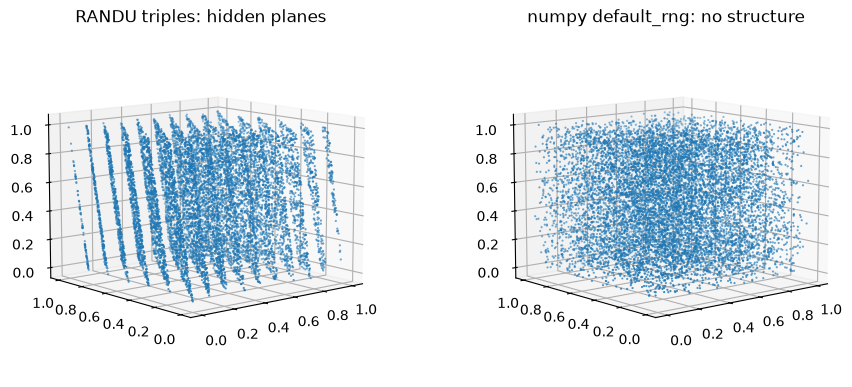

In [2]:
# BLOCK 10.1.1
def lcg(n, seed=1, a=65539, c=0, m=2**31):
    x = np.zeros(n, dtype=np.int64)
    x[0] = seed
    for i in range(1, n):
        x[i] = (a*x[i-1] + c) % m
    return x / m

u = lcg(30000)
fig = plt.figure(figsize=(11, 4.5))
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.scatter(u[:-2:3], u[1:-1:3], u[2::3], s=0.3)
ax1.view_init(elev=10, azim=-130)
ax1.set_title('RANDU triples: hidden planes')

rng = np.random.default_rng(seed=2024)      # modern generator (PCG64)
v = rng.random(30000)
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.scatter(v[:-2:3], v[1:-1:3], v[2::3], s=0.3)
ax2.view_init(elev=10, azim=-130)
ax2.set_title('numpy default_rng: no structure')
plt.show()

In numpy, always use the modern interface: `rng = np.random.default_rng(seed)`, then `rng.random()`, `rng.normal()`, `rng.integers()`, `rng.poisson()`, `rng.choice()` and so on.

# 10.2 Monte Carlo integration <a class="anchor" id="mc-int"></a>
**Hit-or-miss.** Throw darts uniformly at the square $[-1,1]^2$. The fraction landing inside the unit circle is $\pi/4$.

**Mean value method.** More generally, the average of $f$ over $[a,b]$ times the length gives the integral:

$$I = \int_a^b f(x)\,dx \approx \frac{b-a}{N}\sum_{i=1}^N f(x_i), \quad x_i \sim \text{Uniform}(a,b), \qquad \sigma_I \approx (b-a)\frac{\sigma_f}{\sqrt N}.$$

The error estimate comes for free from the sample standard deviation $\sigma_f$ of the $f(x_i)$ values (the central limit theorem).

pi ≈ 3.1060 ± 0.0373


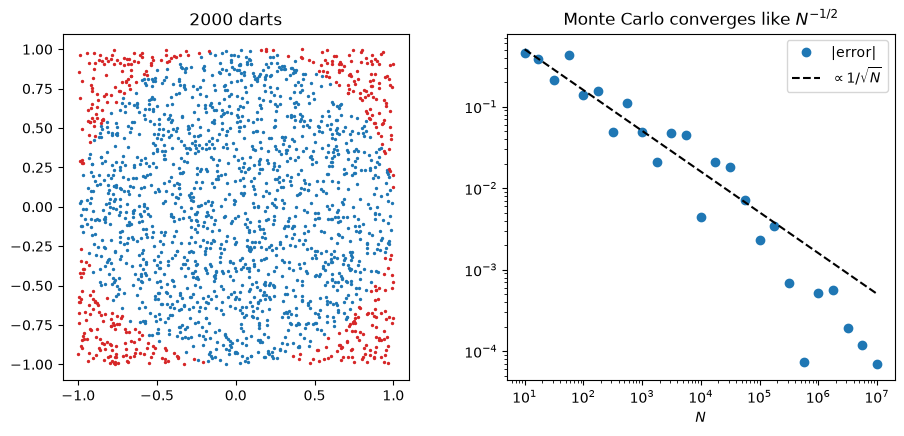

In [3]:
# BLOCK 10.2.1
rng = np.random.default_rng(1)
N = 2000
xy = rng.uniform(-1, 1, size=(N, 2))
inside = np.sum(xy**2, axis=1) < 1
print(f'pi ≈ {4*inside.mean():.4f} ± {4*inside.std()/np.sqrt(N):.4f}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
ax1.scatter(*xy[inside].T, s=2, c='tab:blue'); ax1.scatter(*xy[~inside].T, s=2, c='tab:red')
ax1.set_aspect('equal'); ax1.set_title(f'{N} darts')

Ns = np.logspace(1, 7, 25).astype(int)
errors = [abs(4*np.mean(np.sum(rng.uniform(-1, 1, (n, 2))**2, axis=1) < 1) - np.pi) for n in Ns]
ax2.loglog(Ns, errors, 'o', label='|error|')
ax2.loglog(Ns, 1.6/np.sqrt(Ns), 'k--', label=r'$\propto 1/\sqrt{N}$')
ax2.set_xlabel('$N$'); ax2.legend(); ax2.set_title('Monte Carlo converges like $N^{-1/2}$')
plt.show()

$1/\sqrt N$ is *slow*: for one more decimal place we need 100 times more samples. In 1D, Simpson's rule (error $\propto N^{-4}$) wins by miles. So why bother? Read on...

# 10.3 The curse of dimensionality <a class="anchor" id="dimensions"></a>
A grid-based rule with $n$ points per axis needs $N=n^d$ points in $d$ dimensions, so its error in terms of total points is $\propto N^{-p/d}$. For Simpson ($p=4$) in $d=10$ dimensions that's $N^{-0.4}$ - already worse than Monte Carlo's $N^{-0.5}$, which **doesn't depend on $d$ at all**. In statistical mechanics, where an integral over all particle positions might have $d=3\times10^{23}$ dimensions, Monte Carlo is the only option.

**Example:** the volume of a unit ball in $d$ dimensions, $V_d = \pi^{d/2}/\Gamma(d/2+1)$.

In [4]:
# BLOCK 10.3.1
from scipy.special import gamma

N = 1_000_000
print(' d   Monte Carlo             exact      grid points needed for 10 per axis')
for d in [2, 3, 5, 8, 10, 12]:
    pts = rng.uniform(-1, 1, size=(N, d))
    hits = np.sum(pts**2, axis=1) < 1
    V = 2**d * hits.mean()
    dV = 2**d * hits.std()/np.sqrt(N)
    print(f'{d:>2}   {V:.4f} ± {dV:.4f}      {np.pi**(d/2)/gamma(d/2 + 1):.4f}     10^{d}')

 d   Monte Carlo             exact      grid points needed for 10 per axis
 2   3.1406 ± 0.0016      3.1416     10^2
 3   4.1905 ± 0.0040      4.1888     10^3


 5   5.2786 ± 0.0119      5.2638     10^5
 8   4.0937 ± 0.0321      4.0587     10^8


10   2.4873 ± 0.0504      2.5502     10^10
12   1.3599 ± 0.0746      1.3353     10^12


Notice the relative error grows with $d$: almost all of a high-dimensional cube is in its corners, so very few darts hit the ball. This motivates **importance sampling**.

# 10.4 Sampling from a distribution: inverse transform and rejection <a class="anchor" id="sampling"></a>
Physics simulations need random numbers from non-uniform distributions: exponential path lengths of photons, Maxwell-Boltzmann speeds, angular distributions of decays...

**Inverse transform method.** If $F(x)=\int_{-\infty}^x p(x')dx'$ is the cumulative distribution and $u\sim\text{Uniform}(0,1)$, then $x=F^{-1}(u)$ is distributed according to $p$. E.g. for the free path of a photon, $p(x)=\frac{1}{\lambda}e^{-x/\lambda}$ gives $x = -\lambda\ln(1-u)$.

**Rejection method.** If $F^{-1}$ is unknown, enclose $p(x)$ in a box (or under any envelope you can sample) of height $p_\text{max}$. Pick $x$ uniformly, pick $y$ uniformly in $[0,p_\text{max}]$, and keep $x$ only if $y<p(x)$. Simple, but wasteful if the box is mostly empty.

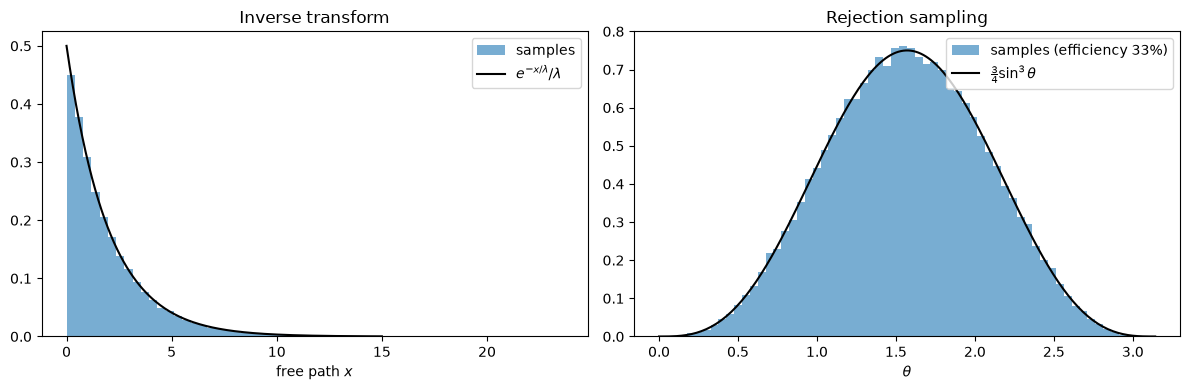

In [5]:
# BLOCK 10.4.1
lam = 2.0
u = rng.random(100_000)
paths = -lam*np.log(1 - u)                                 # inverse transform

# Rejection sampling: angular distribution of dipole radiation, p(theta) ∝ sin^3(theta) on [0, pi]
def rejection(p, a, b, pmax, n):
    samples = []
    tries = 0
    while len(samples) < n:
        x = rng.uniform(a, b, n)
        y = rng.uniform(0, pmax, n)
        samples.extend(x[y < p(x)])
        tries += n
    return np.array(samples[:n]), n/tries

theta, efficiency = rejection(lambda th: np.sin(th)**3, 0, np.pi, 1.0, 100_000)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.hist(paths, bins=60, density=True, alpha=0.6, label='samples')
xx = np.linspace(0, 15, 200); ax1.plot(xx, np.exp(-xx/lam)/lam, 'k', label='$e^{-x/\\lambda}/\\lambda$')
ax1.set_xlabel('free path $x$'); ax1.legend(); ax1.set_title('Inverse transform')
ax2.hist(theta, bins=60, density=True, alpha=0.6, label=f'samples (efficiency {efficiency:.0%})')
th = np.linspace(0, np.pi, 200); ax2.plot(th, 0.75*np.sin(th)**3, 'k', label=r'$\frac{3}{4}\sin^3\theta$')
ax2.set_xlabel(r'$\theta$'); ax2.legend(); ax2.set_title('Rejection sampling')
plt.tight_layout(); plt.show()

# 10.5 Importance sampling <a class="anchor" id="importance"></a>
If $f$ is sharply peaked, uniform sampling wastes most of its points where $f\approx0$. Instead, draw $x_i$ from a distribution $w(x)$ shaped like $f$ and correct for it:

$$I=\int f(x)\,dx = \int \frac{f(x)}{w(x)}w(x)\,dx \approx \frac1N\sum_{i}\frac{f(x_i)}{w(x_i)}, \qquad x_i\sim w.$$

If $f/w$ is nearly constant the variance - and hence the error - is tiny.

**Example:** $I=\int_0^\infty \frac{e^{-x}}{1+x^2}dx$. Uniform sampling on a truncated range vs sampling from $w(x)=e^{-x}$ (which we can generate by inverse transform).

In [6]:
# BLOCK 10.5.1
from scipy.integrate import quad
f = lambda x: np.exp(-x)/(1 + x**2)
I_exact = quad(f, 0, np.inf)[0]

N = 10_000
x_u = rng.uniform(0, 20, N)
vals_u = 20*f(x_u)
x_w = -np.log(1 - rng.random(N))          # samples from w(x) = e^{-x}
vals_w = f(x_w)/np.exp(-x_w)               # = 1/(1+x^2): nearly flat!

print(f'exact               : {I_exact:.5f}')
print(f'uniform sampling    : {vals_u.mean():.5f} ± {vals_u.std()/np.sqrt(N):.5f}')
print(f'importance sampling : {vals_w.mean():.5f} ± {vals_w.std()/np.sqrt(N):.5f}')

exact               : 0.62145
uniform sampling    : 0.61233 ± 0.02525
importance sampling : 0.62259 ± 0.00310


Same number of samples, roughly an order of magnitude smaller error - equivalent to using ~50-100$\times$ more samples, because the error only falls as $1/\sqrt N$.

# 10.6 Random walks and diffusion <a class="anchor" id="random-walk"></a>
A pollen grain in water (Brownian motion), a photon escaping the Sun, a molecule of perfume crossing a room: each takes a sequence of random steps. After $N$ steps of length $\ell$ in random directions, the **mean** displacement is zero, but the **root-mean-square** displacement grows as

$$\sqrt{\langle R^2\rangle} = \ell\sqrt{N}.$$

This $\sqrt{N}$ (or $\sqrt{t}$) law is the microscopic origin of the diffusion equation from Chapter 7, with $\langle x^2\rangle = 2Dt$ in each dimension. Einstein used exactly this relation in 1905 to prove that atoms exist.

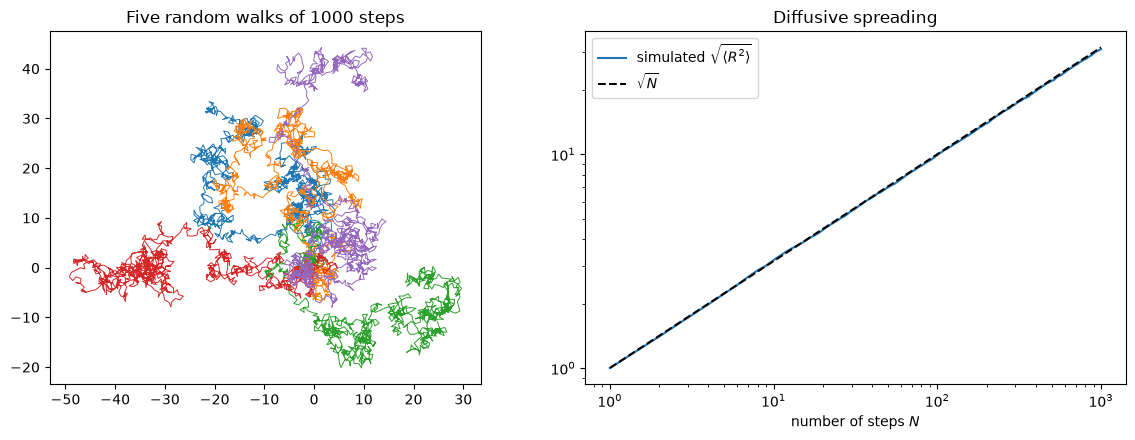

In [7]:
# BLOCK 10.6.1
n_walkers, n_steps = 2000, 1000
angles = rng.uniform(0, 2*np.pi, size=(n_walkers, n_steps))
steps = np.stack([np.cos(angles), np.sin(angles)], axis=-1)   # unit steps
paths = np.cumsum(steps, axis=1)                              # positions after each step
R2 = np.mean(np.sum(paths**2, axis=-1), axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for k in range(5):
    ax1.plot(paths[k, :, 0], paths[k, :, 1], lw=0.7)
ax1.set_aspect('equal'); ax1.set_title('Five random walks of 1000 steps')
n = np.arange(1, n_steps + 1)
ax2.loglog(n, np.sqrt(R2), label=r'simulated $\sqrt{\langle R^2 \rangle}$')
ax2.loglog(n, np.sqrt(n), 'k--', label=r'$\sqrt{N}$')
ax2.set_xlabel('number of steps $N$'); ax2.legend(); ax2.set_title('Diffusive spreading')
plt.tight_layout(); plt.show()

# 10.7 Markov Chain Monte Carlo: the Metropolis algorithm <a class="anchor" id="metropolis"></a>
In statistical mechanics we need averages over the Boltzmann distribution $p(\mathbf x) \propto e^{-E(\mathbf x)/k_BT}$ in a huge configuration space, where we can't even compute the normalising constant (the partition function $Z$). The **Metropolis algorithm** (1953) generates a chain of samples with the right distribution using only *ratios* of probabilities:

1. From the current state $\mathbf x$, propose a small random change $\mathbf x'$.
2. Compute $\Delta E = E(\mathbf x') - E(\mathbf x)$.
3. If $\Delta E \le 0$, accept. Otherwise accept with probability $e^{-\Delta E/k_BT}$.
4. If rejected, the chain stays at $\mathbf x$ (and $\mathbf x$ is counted **again**).

This is consistent with *detailed balance*, which guarantees that the chain eventually samples $p(\mathbf x)$. Let's test it on a particle in a double-well potential $E(x)=(x^2-1)^2$, whose Boltzmann distribution we can compute exactly for comparison.

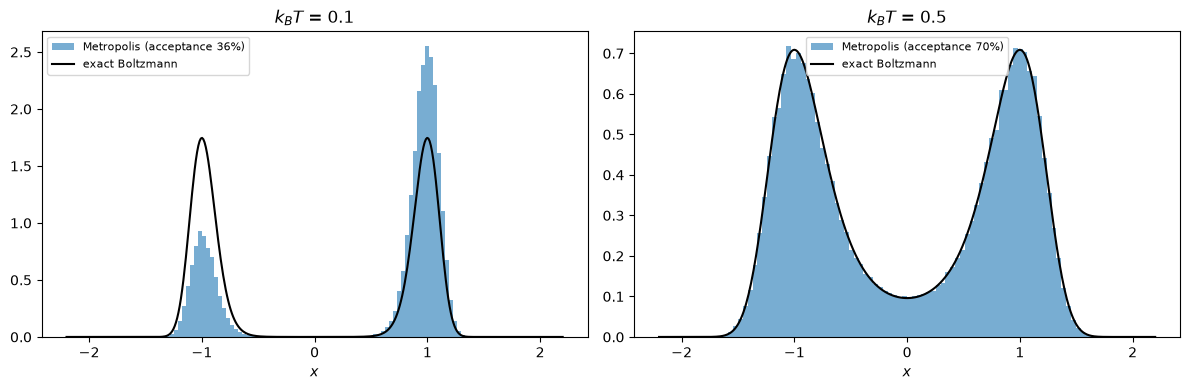

In [8]:
# BLOCK 10.7.1
def metropolis(E, x0, kT, n_samples, step=0.5):
    x = x0
    chain = np.zeros(n_samples)
    accepted = 0
    for i in range(n_samples):
        x_new = x + rng.uniform(-step, step)
        dE = E(x_new) - E(x)
        if dE <= 0 or rng.random() < np.exp(-dE/kT):
            x = x_new
            accepted += 1
        chain[i] = x
    return chain, accepted/n_samples

E = lambda x: (x**2 - 1)**2
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
xx = np.linspace(-2.2, 2.2, 400)
for ax, kT in zip(axes, [0.1, 0.5]):
    chain, acc = metropolis(E, 1.0, kT, 200_000)
    p = np.exp(-E(xx)/kT); p /= np.trapezoid(p, xx)
    ax.hist(chain[1000:], bins=80, density=True, alpha=0.6, label=f'Metropolis (acceptance {acc:.0%})')
    ax.plot(xx, p, 'k', label='exact Boltzmann')
    ax.set_title(f'$k_BT$ = {kT}'); ax.set_xlabel('$x$'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

We discarded the first 1000 samples as **burn-in** (the chain needs time to forget its starting point). In the Statistical Physics applications notebook we'll use exactly this algorithm to simulate a magnet with the Ising model.

# 10.8 Simulated annealing <a class="anchor" id="annealing"></a>
Turn Metropolis into an **optimiser**: run it while slowly *lowering* the temperature. At high $T$ it explores freely and can escape local minima; as $T\to0$ it settles into (hopefully) the global minimum - just like a metal slowly cooled into a near-perfect crystal. It's useful for horribly bumpy landscapes where Newton-type methods get stuck.

annealing found x = -0.6056, E = -1.9451;  brute-force grid minimum E = -1.9458


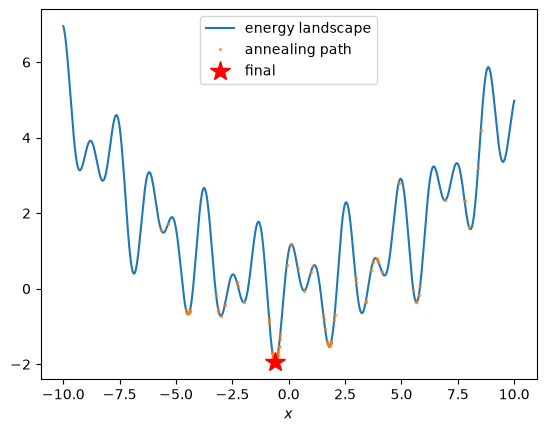

In [9]:
# BLOCK 10.8.1
bumpy = lambda x: x**2/20 + np.sin(3*x) + np.cos(5*x)       # many local minima
x, kT = 8.0, 3.0
history = [x]
while kT > 1e-3:
    for _ in range(50):
        x_new = x + rng.normal(0, 0.5)
        dE = bumpy(x_new) - bumpy(x)
        if dE <= 0 or rng.random() < np.exp(-dE/kT):
            x = x_new
    history.append(x)
    kT *= 0.97                                              # cooling schedule

xg = np.linspace(-10, 10, 4000)
print(f'annealing found x = {x:.4f}, E = {bumpy(x):.4f};  brute-force grid minimum E = {bumpy(xg).min():.4f}')
plt.plot(xg, bumpy(xg), label='energy landscape')
plt.plot(history, bumpy(np.array(history)), '.', ms=3, alpha=0.6, label='annealing path')
plt.plot(x, bumpy(x), 'r*', ms=15, label='final')
plt.xlabel('$x$'); plt.legend(); plt.show()

# Problems <a class="anchor" id="problems"></a>

### Exercise 1 - Buffon's needle
Drop needles of length $\ell$ onto a floor of parallel lines spaced $d\ge\ell$ apart. The probability a needle crosses a line is $2\ell/(\pi d)$. Simulate this to estimate $\pi$ and check the $1/\sqrt N$ convergence.

### Exercise 2 - Maxwell-Boltzmann speeds
Sample molecular velocities by drawing each Cartesian component from a normal distribution with variance $k_BT/m$. Histogram the speeds and compare with the Maxwell-Boltzmann distribution. Compute $\langle v\rangle$ and $\langle v^2\rangle$ by Monte Carlo and compare with $\sqrt{8k_BT/\pi m}$ and $3k_BT/m$.

### Exercise 3 - Photon escape from the Sun
A photon in the solar core scatters with a mean free path of roughly 1 mm. Simulate a 3D random walk with exponentially distributed step lengths (use the inverse transform method) in a sphere of radius $R$ for several (small!) $R$ and show that the number of steps to escape scales as $R^2/\ell^2$. Extrapolate to $R_\odot\approx7\times10^8$ m: how long does sunlight take to leave the Sun?

### Exercise 4 - A 6D integral
Compute $\displaystyle\int_{[0,1]^6} e^{-|\mathbf x|^2}\,d^6x$ by Monte Carlo and by a 6D trapezium rule with the same total number of points. Which wins? (The exact answer is $\left(\frac{\sqrt\pi}{2}\mathrm{erf}(1)\right)^6$.)

In [10]:
# Start working here

---
<details>
<summary>🥚</summary>

This is a deliberate easter egg, not part of the course, and nothing in it is examinable. Run the cell below.
</details>

In [11]:
# Easter egg (deliberate, not part of the course): darts at a square, with a fixed seed.
import math, random

rng = random.Random(1777)                  # 1777: the year Buffon published his needle problem
N = 200_000
hits = sum(1 for _ in range(N) if rng.random()**2 + rng.random()**2 < 1)
pi_est = 4*hits/N
expected = 4*math.sqrt(0.25*math.pi*(1 - 0.25*math.pi)/N)
print(f"pi ≈ {pi_est:.5f}, error = {pi_est - math.pi:+.5f} (typical size of the error ~ {expected:.4f})")
print("Buffon would be proud.")

pi ≈ 3.14760, error = +0.00601 (typical size of the error ~ 0.0037)
Buffon would be proud.
